# 1. Chargement des données

Dataset link: https://www.kaggle.com/datasets/ronil8/diamond-price-prediction-dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
dataset = pd.read_csv("dataset.csv")

# 2. Analyse exploratoire (EDA)

In [2]:
dataset.head(10)

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,6,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,7,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,8,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,9,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,10,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


* price: price in US dollars ($326-$18,823) (numérique, target)
* carat: weight of the diamond (0.2-5.01) (numérique)
* cut: quality of the cut (Fair, Good, Very Good, Premium, Ideal) (ordinale)
* color: diamond color (J (worst) to D (best)) (ordinale)
* clarity: measurement of how clear the diamond is (I1 (worst), SI2, SI1, VS2, VS1, VVS2, 
VVS1, IF (best)) (ordinale)
* x: length in mm (0-10.74) (numérique)
* y: width in mm (0-58.9) (numérique)
* z: depth in mm (0-31.8) (numérique)
* depth: total depth percentage (43-79) (numérique)
* table: width of top of diamond relative to widest point (43-95) (numérique)

In [3]:
# (nombre de lignes, nombre de colonnes)
dataset.shape

(53940, 11)

In [4]:
# des informations sur le jeu de données
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [5]:
# lister les valeurs catégorielles
dataset.select_dtypes(include="object").columns

Index(['cut', 'color', 'clarity'], dtype='object')

In [6]:
# la taille des valeurs catégorielles
len(dataset.select_dtypes(include="object").columns)

3

In [7]:
# lister les valeurs numeriques
dataset.select_dtypes(include="number").columns

Index(['Unnamed: 0', 'carat', 'depth', 'table', 'price', 'x', 'y', 'z'], dtype='object')

In [8]:
# la taille des valeurs numériques
len(dataset.select_dtypes(include="number").columns)

8

In [9]:
# les statistiques
dataset.describe(include="all")

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940,53940,53940,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
unique,NaN,NaN,5,7,8,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Ideal,G,SI1,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,21551,11292,13065,NaN,NaN,NaN,NaN,NaN,NaN
mean,26970.500000,0.797940,NaN,NaN,NaN,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,NaN,NaN,NaN,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,NaN,NaN,NaN,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,NaN,NaN,NaN,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,NaN,NaN,NaN,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,NaN,NaN,NaN,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000


In [10]:
# lister totues les colonnes
dataset.columns

Index(['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table',
       'price', 'x', 'y', 'z'],
      dtype='object')

# 3. Gestion des valeurs manquantes

In [11]:
# vérifier si il existe des valeurs manquantes dans le jeu de données
dataset.isnull().values.any()

False

In [12]:
# le nombre de valeurs manquantes dans le jeu de données
dataset.isnull().values.sum()

0

In [13]:
# lister les valeurs manquantes
dataset.isna().sum()

Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64

# 4. Visualisations

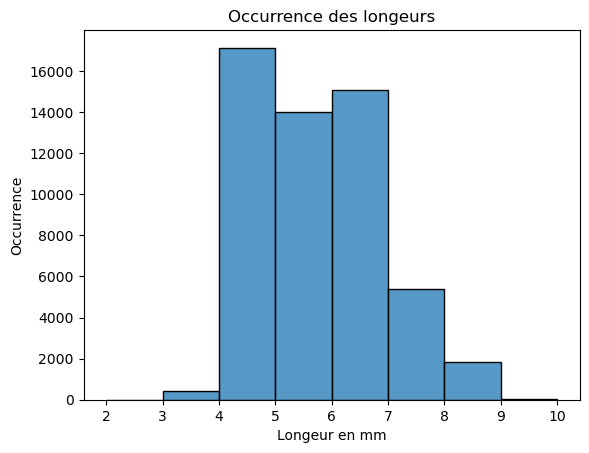

In [14]:
# L'occurence des longeurs
sns.histplot(data=dataset, x="x", bins=range(2, 11))
plt.xlabel("Longeur en mm")
plt.ylabel("Occurrence")
plt.title("Occurrence des longeurs")
plt.show()

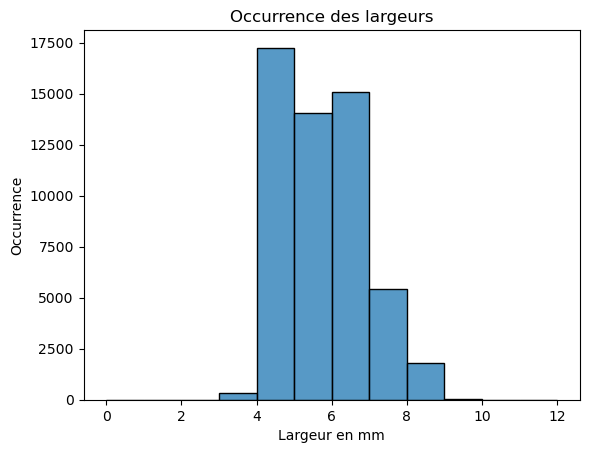

In [15]:
# L'occurence des largeurs
sns.histplot(data=dataset, x="y", bins=range(0, 13))
plt.xlabel("Largeur en mm")
plt.ylabel("Occurrence")
plt.title("Occurrence des largeurs")
plt.show()

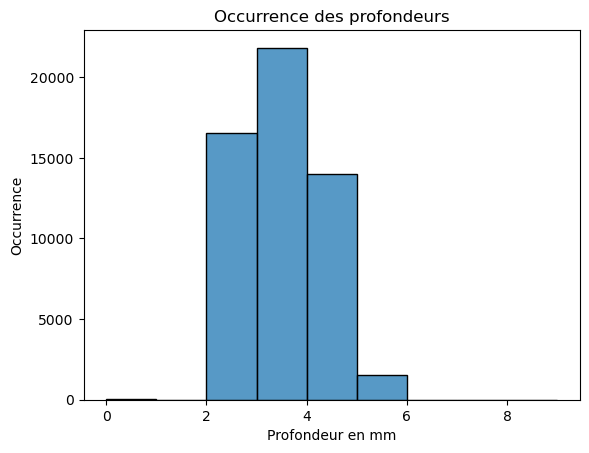

In [16]:
# L'occurence des profondeurs
sns.histplot(data=dataset, x="z", bins=range(0, 10))
plt.xlabel("Profondeur en mm")
plt.ylabel("Occurrence")
plt.title("Occurrence des profondeurs")
plt.show()

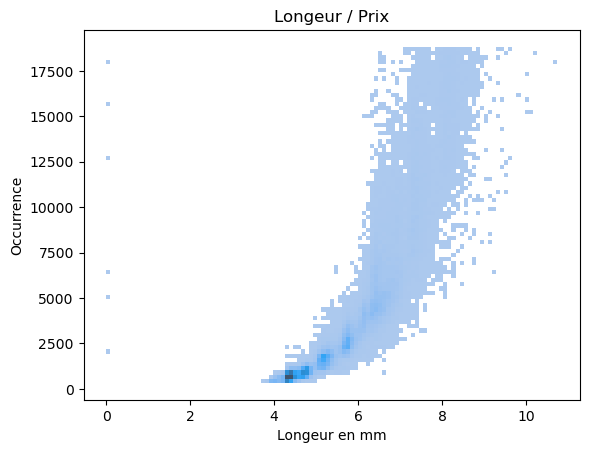

In [17]:
# Les longeurs par rapport au prix
sns.histplot(data=dataset, x="x", y="price")
plt.xlabel("Longeur en mm")
plt.ylabel("Occurrence")
plt.title("Longeur / Prix")
plt.show()

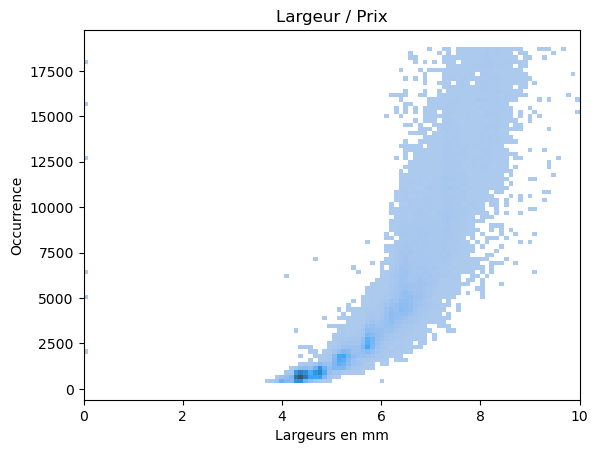

In [18]:
# Les largeurs par rapport au prix
sns.histplot(data=dataset, x="y", y="price", )
plt.xlabel("Largeurs en mm")
plt.xlim((0, 10))
plt.ylabel("Occurrence")
plt.title("Largeur / Prix")
plt.show()

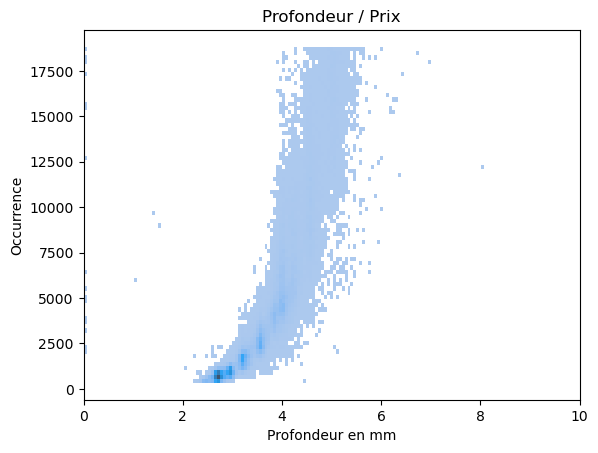

In [19]:
# Les profondeurs par rapport au prix
sns.histplot(data=dataset, x="z", y="price", )
plt.xlabel("Profondeur en mm")
plt.xlim((0, 10))
plt.ylabel("Occurrence")
plt.title("Profondeur / Prix")
plt.show()

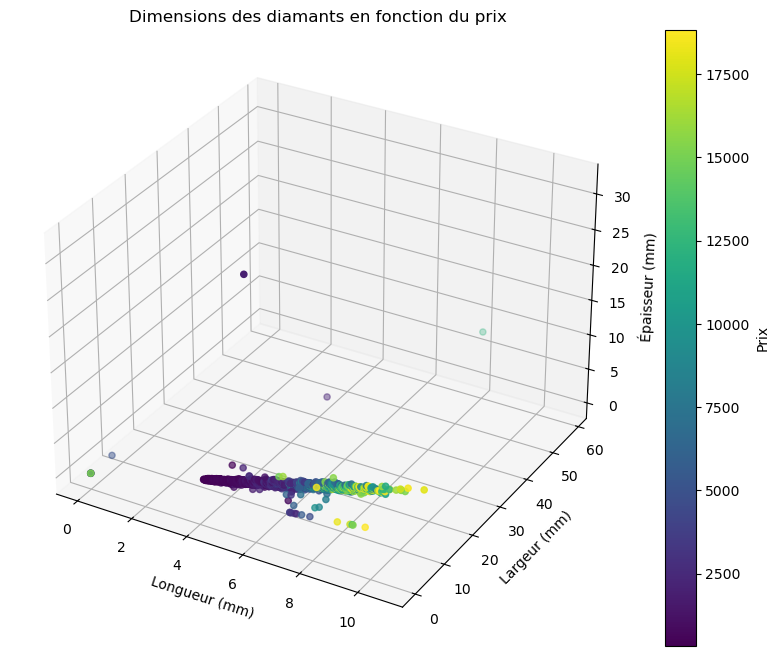

In [20]:
# les 3 dimensions (longeur, largeur, épaisseur) par rapport au prix (visualisation en 3D)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_3D(df):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    scatter = ax.scatter(
        df["x"],
        df["y"],
        df["z"],
        c=df["price"],
        cmap="viridis"
    )

    ax.set_xlabel("Longueur (mm)")
    ax.set_ylabel("Largeur (mm)")
    ax.set_zlabel("Épaisseur (mm)")

    fig.colorbar(scatter, ax=ax, label="Prix")

    plt.title("Dimensions des diamants en fonction du prix")
    plt.show()

plot_3D(dataset)

# 5. Nettoyage des données

In [21]:
# supprimer la 1ère colonne 'Unnamed: 0'
dataset = dataset.drop(['Unnamed: 0'], axis = 1)

In [22]:
# vérifier les valeurs catégorielles
dataset.select_dtypes(include="object").columns

Index(['cut', 'color', 'clarity'], dtype='object')

In [23]:
# les valeurs catégorielles dans 'cut'
dataset["cut"].unique()

array(['Ideal', 'Premium', 'Good', 'Very Good', 'Fair'], dtype=object)

In [24]:
# le nombre des valeurs catégorielles dans 'cut'
dataset["cut"].nunique()

5

In [25]:
# les valeurs catégorielles dans 'color'
dataset["color"].unique()

array(['E', 'I', 'J', 'H', 'F', 'G', 'D'], dtype=object)

In [26]:
# le nombre des valeurs catégorielles dans 'color'
dataset["color"].nunique()

7

In [27]:
# les valeurs catégorielles dans 'clarity'
dataset["clarity"].unique()

array(['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF'],
      dtype=object)

In [28]:
# le nombre des valeurs catégorielles dans 'clarity'
dataset["clarity"].nunique()

8

In [29]:
# regrouper les valeurs numériques par 'cut' (qualité)
dataset.groupby("cut").mean(numeric_only=True)

,carat,depth,table,price,x,y,z
cut,,,,,,,
Fair,1.046137,64.041677,59.053789,4358.757764,6.246894,6.182652,3.982770
Good,0.849185,62.365879,58.694639,3928.864452,5.838785,5.850744,3.639507
Ideal,0.702837,61.709401,55.951668,3457.541970,5.507451,5.520080,3.401448
Premium,0.891955,61.264673,58.746095,4584.257704,5.973887,5.944879,3.647124
Very Good,0.806381,61.818275,57.956150,3981.759891,5.740696,5.770026,3.559801


In [30]:
# regrouper les valeurs numériques par 'color'
dataset.groupby("color").mean(numeric_only=True)

,carat,depth,table,price,x,y,z
color,,,,,,,
D,0.657795,61.698125,57.404590,3169.954096,5.417051,5.421128,3.342827
E,0.657867,61.662090,57.491201,3076.752475,5.411580,5.419029,3.340689
F,0.736538,61.694582,57.433536,3724.886397,5.614961,5.619456,3.464446
G,0.771190,61.757111,57.288629,3999.135671,5.677543,5.680192,3.505021
H,0.911799,61.836850,57.517811,4486.669196,5.983335,5.984815,3.695965
I,1.026927,61.846385,57.577278,5091.874954,6.222826,6.222730,3.845411
J,1.162137,61.887215,57.812393,5323.818020,6.519338,6.518105,4.033251


In [31]:
# regrouper les valeurs numériques par 'clarity'
dataset.groupby("clarity").mean(numeric_only=True)

,carat,depth,table,price,x,y,z
clarity,,,,,,,
I1,1.283846,62.734278,58.303779,3924.168691,6.761093,6.709379,4.207908
IF,0.505123,61.510615,56.507207,2864.839106,4.968402,4.989827,3.061659
SI1,0.850482,61.853042,57.662541,3996.001148,5.888383,5.888256,3.639845
SI2,1.077648,61.772167,57.927181,5063.028606,6.401370,6.397826,3.948478
VS1,0.727158,61.667458,57.315151,3839.455391,5.572178,5.581828,3.441007
VS2,0.763935,61.724417,57.417401,3924.989395,5.657709,5.658859,3.491478
VVS1,0.503321,61.624651,56.884460,2523.114637,4.960364,4.975075,3.061294
VVS2,0.596202,61.663778,57.024990,3283.737071,5.218454,5.232118,3.221465


In [32]:
dataset["cut"].value_counts()

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

In [33]:
dataset["clarity"].value_counts()

clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64

In [34]:
dataset["color"].value_counts()

color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

In [35]:
# encoder les données catégorielles (one-hot encoding)
dataset = pd.get_dummies(data=dataset)

In [36]:
dataset.head()

,carat,depth,table,price,x,y,z,cut_Fair,cut_Good,cut_Ideal,...,color_I,color_J,clarity_I1,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,61.5,55.0,326,3.95,3.98,2.43,False,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0.21,59.8,61.0,326,3.89,3.84,2.31,False,False,False,...,False,False,False,False,True,False,False,False,False,False
2,0.23,56.9,65.0,327,4.05,4.07,2.31,False,True,False,...,False,False,False,False,False,False,True,False,False,False
3,0.29,62.4,58.0,334,4.20,4.23,2.63,False,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,63.3,58.0,335,4.34,4.35,2.75,False,True,False,...,False,True,False,False,False,True,False,False,False,False


## Matrice de Correlation et Heatmap

<Axes: title={'center': 'Correlation avec prix'}>

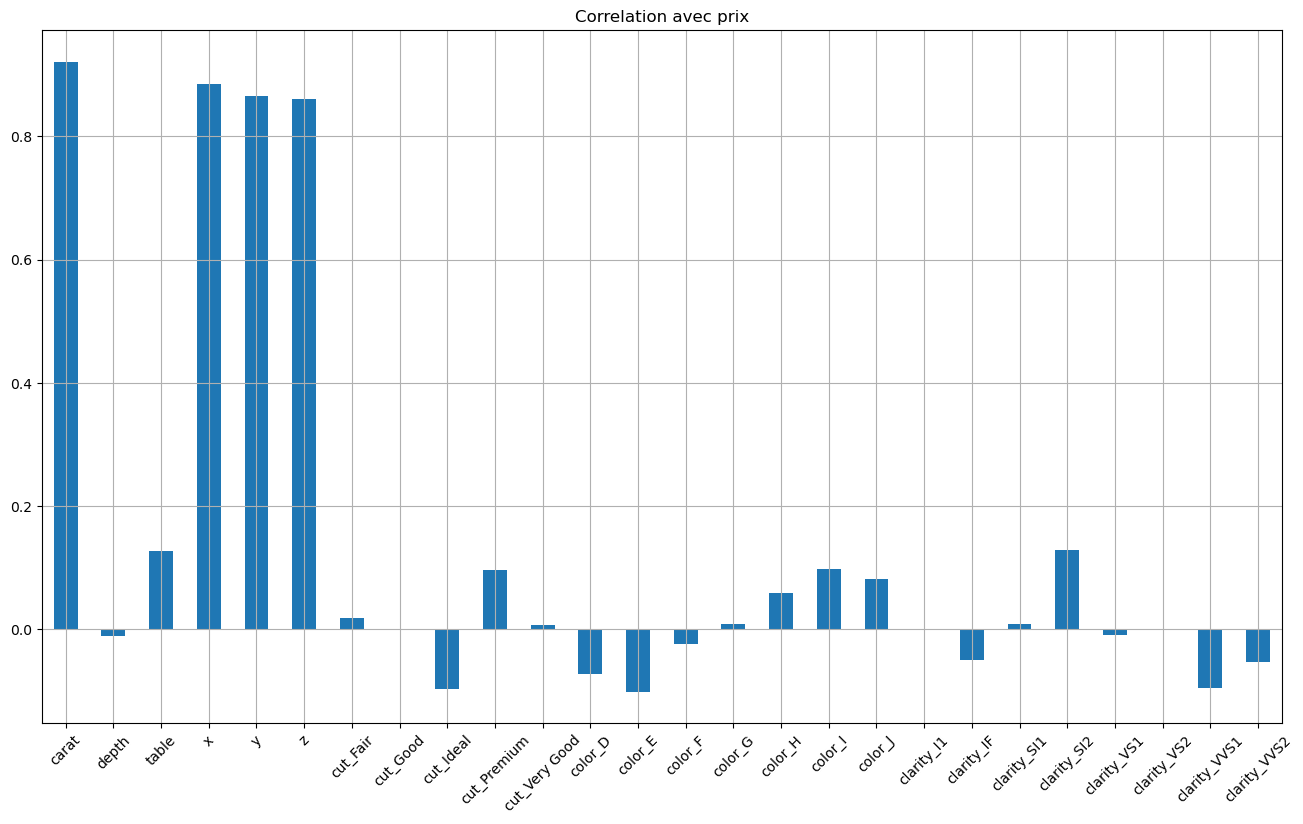

In [37]:
dataset_2 = dataset.drop(columns="price")
dataset_2.corrwith(dataset["price"]).plot.bar(
    figsize = (16, 9),
    title = "Correlation avec prix",
    rot = 45,
    grid = True
)

<Axes: >

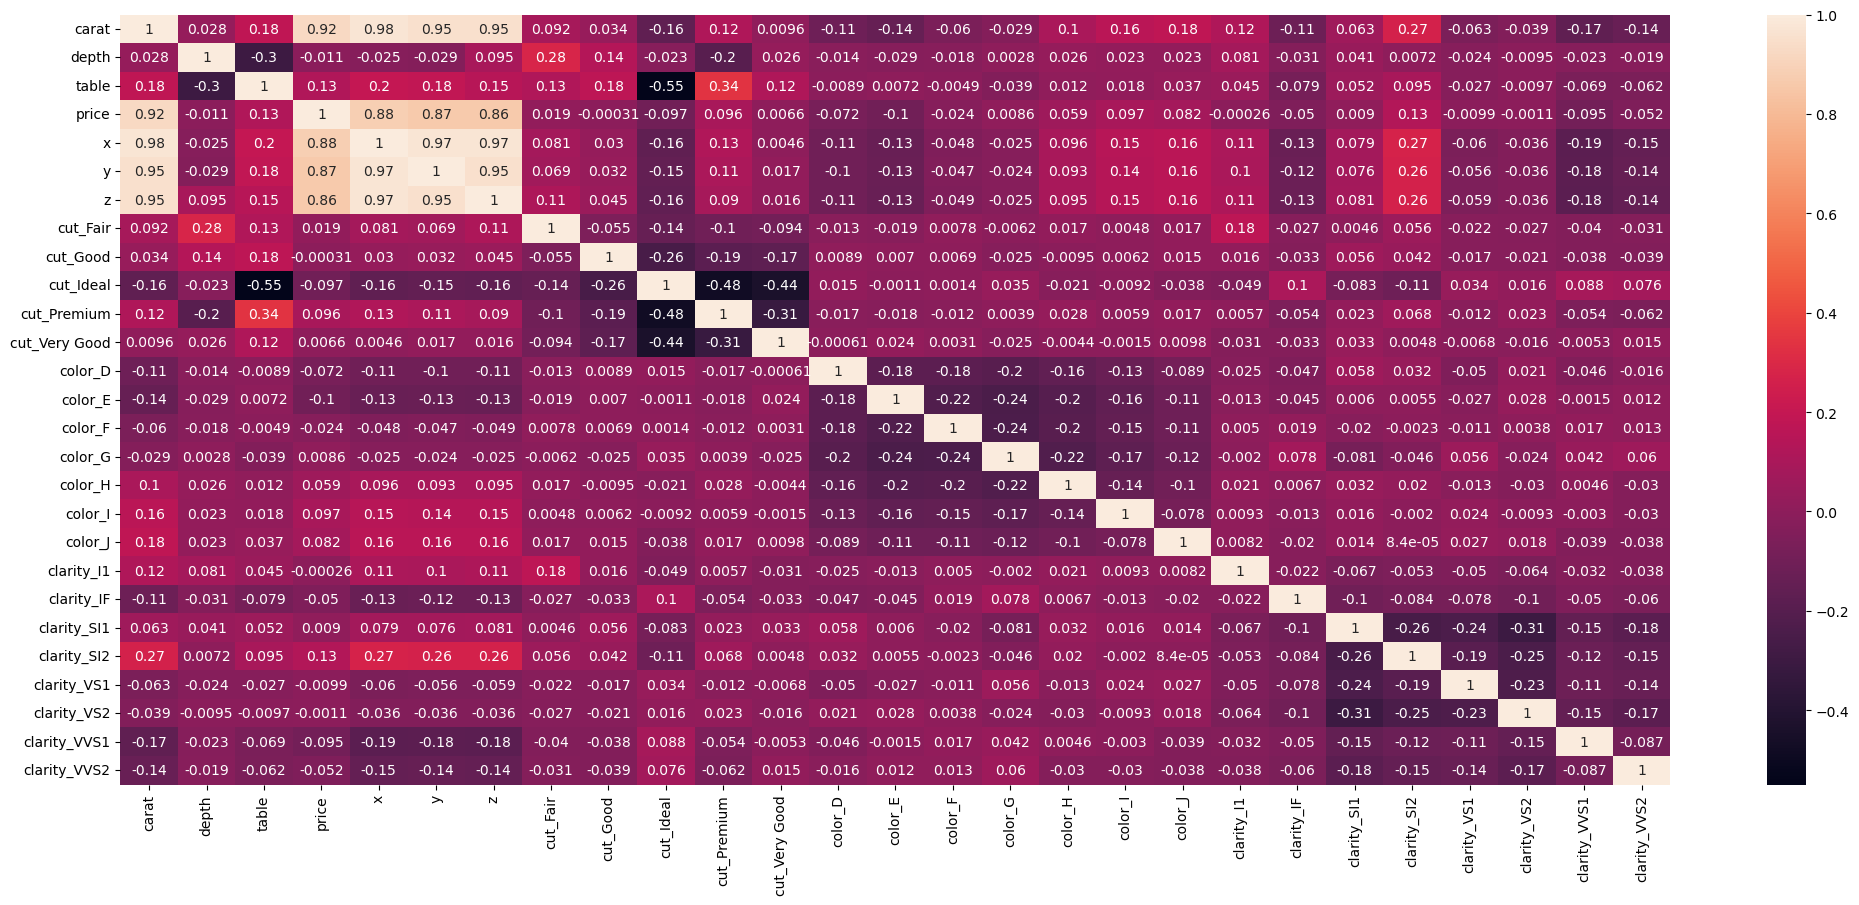

In [38]:
corr = dataset.corr()
plt.figure(figsize = (25, 10))
sns.heatmap(corr, annot = True)

# 6. Train, Test, Split

In [39]:
# variables indépendantes / matrice des features
x = dataset.drop(columns="price")

# target = variable cible / variable dépendante
y = dataset["price"]

In [40]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=0)

In [41]:
x_train.shape

(43152, 26)

In [42]:
x_test.shape

(10788, 26)

In [43]:
y_train.shape

(43152,)

In [44]:
y_test.shape

(10788,)

In [45]:
# Feature scaling (mettre toutes les variables à la même échelle)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [46]:
x_train

array([[ 1.75203254, -0.03658289, -1.10009927, ..., -0.5416365 ,
        -0.26955338, -0.32345093],
       [-0.96506823,  0.31236163, -0.20388839, ...,  1.84625666,
        -0.26955338, -0.32345093],
       [-0.83869145, -0.03658289, -0.65199383, ..., -0.5416365 ,
        -0.26955338,  3.09165906],
       ...,
       [-1.00719383, -0.31573851,  0.24421705, ..., -0.5416365 ,
        -0.26955338, -0.32345093],
       [-0.81762866, -0.52510522, -0.20388839, ..., -0.5416365 ,
        -0.26955338, -0.32345093],
       [ 0.23551118, -0.45531632, -1.10009927, ..., -0.5416365 ,
        -0.26955338, -0.32345093]])

In [47]:
x_test

array([[ 0.63570431,  0.17278382, -1.10009927, ..., -0.5416365 ,
        -0.26955338, -0.32345093],
       [ 1.03589745,  0.59151724, -0.65199383, ..., -0.5416365 ,
        -0.26955338, -0.32345093],
       [ 0.84633228, -0.45531632,  0.24421705, ..., -0.5416365 ,
        -0.26955338, -0.32345093],
       ...,
       [ 0.59357872,  1.14982848, -1.10009927, ..., -0.5416365 ,
        -0.26955338, -0.32345093],
       [ 0.46720194, -0.1761607 , -0.20388839, ..., -0.5416365 ,
         3.70984027, -0.32345093],
       [-0.62806349,  2.12687314,  0.24421705, ..., -0.5416365 ,
        -0.26955338,  3.09165906]])

In [48]:
# sauvegarder le jeu d'entraînement et le jeu de test
np.savetxt("./x_train.csv", x_train, delimiter=",")
np.savetxt("./X_test.csv", x_test, delimiter=",")

# 6. Création du modèle

## Régression Linéaire

In [49]:
from sklearn.linear_model import LinearRegression

# créer le modèle
model_lr = LinearRegression()

# entraîner le modèle
model_lr.fit(x_train, y_train)

LinearRegression()

In [50]:
# faire des predictions / le jeu de test
y_pred = model_lr.predict(x_test)

In [51]:
from sklearn.metrics import confusion_matrix, mean_squared_error, mean_absolute_error, r2_score

# calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# création du tableau des résultats
lr_results = pd.DataFrame(
    [["Linear Regression", rmse, mae, r2]],
    columns=["Model", "RMSE", "MAE", "R2"]
)

lr_results

,Model,RMSE,MAE,R2
0,Linear Regression,1117.619972,738.598466,0.921202


### Validation croisée

In [52]:
from sklearn.model_selection import cross_val_score

accuracies = cross_val_score(estimator=model_lr, X=x_train, y=y_train, cv=10)

print("Accuracy is {:.2f} %".format(accuracies.mean() * 100))
print("Standard Deviation is {:.2f} %".format(accuracies.std() * 100))

Accuracy is 91.92 %
Standard Deviation is 0.48 %


## Régression avec les k plus proches voisins

In [53]:
from sklearn.neighbors import KNeighborsRegressor

# créer le modèle
model_knn = KNeighborsRegressor()

# entraîner le modèle
model_knn.fit(x_train, y_train)

KNeighborsRegressor()

In [54]:
# faire des predictions / le jeu de test
y_pred = model_knn.predict(x_test)

In [55]:
# calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# création du tableau des résultats
knn_results = pd.DataFrame(
    [["K Neighbors Regressor", rmse, mae, r2]],
    columns=["Model", "RMSE", "MAE", "R2"]
)

knn_results

,Model,RMSE,MAE,R2
0,K Neighbors Regressor,866.418173,424.79518,0.952643


In [56]:
results = pd.concat([lr_results, knn_results], ignore_index=True)
results

,Model,RMSE,MAE,R2
0,Linear Regression,1117.619972,738.598466,0.921202
1,K Neighbors Regressor,866.418173,424.795180,0.952643


### Validation croisée

In [57]:
accuracies = cross_val_score(estimator=model_knn, X=x_train, y=y_train, cv=10)

print("Accuracy is {:.2f} %".format(accuracies.mean() * 100))
print("Standard Deviation is {:.2f} %".format(accuracies.std() * 100))

Accuracy is 95.17 %
Standard Deviation is 0.34 %


## Régression avec un arbre de décision

In [58]:
from sklearn.tree import DecisionTreeRegressor

# créer le modèle
model_dtr = DecisionTreeRegressor()

# entraîner le modèle
model_dtr.fit(x_train, y_train)

DecisionTreeRegressor()

In [59]:
# faire des predictions / le jeu de test
y_pred = model_dtr.predict(x_test)

In [60]:
# calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# création du tableau des résultats
dtr_results = pd.DataFrame(
    [["Decision Tree Regressor", rmse, mae, r2]],
    columns=["Model", "RMSE", "MAE", "R2"]
)

dtr_results

,Model,RMSE,MAE,R2
0,Decision Tree Regressor,740.248943,355.11726,0.965432


In [61]:
results = pd.concat([results, dtr_results], ignore_index=True)
results

,Model,RMSE,MAE,R2
0,Linear Regression,1117.619972,738.598466,0.921202
1,K Neighbors Regressor,866.418173,424.795180,0.952643
2,Decision Tree Regressor,740.248943,355.117260,0.965432


### Validation croisée

In [62]:
accuracies = cross_val_score(estimator=model_dtr, X=x_train, y=y_train, cv=10)

print("Accuracy is {:.2f} %".format(accuracies.mean() * 100))
print("Standard Deviation is {:.2f} %".format(accuracies.std() * 100))

Accuracy is 96.48 %
Standard Deviation is 0.30 %


# 7. Optimisation du meilleur modèle avec GridSearchCV

In [63]:
from sklearn.model_selection import GridSearchCV

# définir la grille d'hyperparamètres
hyperparameters_tree = {
    "criterion": ["squared_error", "friedman_mse", "absolute_error"],
    "max_depth": range(5, 10)
}

# créer le GridSearchCV
search = GridSearchCV(
    estimator=model_dtr,
    param_grid=hyperparameters_tree,
    cv=4,
    scoring="neg_mean_squared_error",
    verbose=10
)

# entrâiner le modèle
search.fit(x_train, y_train)

Fitting 4 folds for each of 15 candidates, totalling 60 fits
[CV 1/4; 1/15] START criterion=squared_error, max_depth=5.......................
[CV 1/4; 1/15] END criterion=squared_error, max_depth=5;, score=-1399533.229 total time=   0.0s
[CV 2/4; 1/15] START criterion=squared_error, max_depth=5.......................
[CV 2/4; 1/15] END criterion=squared_error, max_depth=5;, score=-1458361.546 total time=   0.0s
[CV 3/4; 1/15] START criterion=squared_error, max_depth=5.......................
[CV 3/4; 1/15] END criterion=squared_error, max_depth=5;, score=-1356277.787 total time=   0.0s
[CV 4/4; 1/15] START criterion=squared_error, max_depth=5.......................
[CV 4/4; 1/15] END criterion=squared_error, max_depth=5;, score=-1371759.983 total time=   0.0s
[CV 1/4; 2/15] START criterion=squared_error, max_depth=6.......................
[CV 1/4; 2/15] END criterion=squared_error, max_depth=6;, score=-1188704.954 total time=   0.0s
[CV 2/4; 2/15] START criterion=squared_error, max_dept

GridSearchCV(cv=4, estimator=DecisionTreeRegressor(),
             param_grid={'criterion': ['squared_error', 'friedman_mse',
                                       'absolute_error'],
                         'max_depth': range(5, 10)},
             scoring='neg_mean_squared_error', verbose=10)

In [64]:
# meilleur modèle
best_model = search.best_estimator_

In [65]:
print("Meilleur score :", search.best_score_)
print("Meilleurs hyperparamètres :", search.best_params_)

Meilleur score : -664449.2310524901
Meilleurs hyperparamètres : {'criterion': 'squared_error', 'max_depth': 9}


# 8. Évaluation finale

In [66]:
# faire des predictions avec le meilleur modèle
y_pred = best_model.predict(x_test)

In [67]:
# calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# création du tableau des résultats
final_dtr_results = pd.DataFrame(
    [["Final Decision Tree Regressor", rmse, mae, r2]],
    columns=["Model", "RMSE", "MAE", "R2"]
)

final_dtr_results

,Model,RMSE,MAE,R2
0,Final Decision Tree Regressor,795.254617,429.179351,0.960103


In [68]:
results = pd.concat([results, final_dtr_results], ignore_index=True)
results

,Model,RMSE,MAE,R2
0,Linear Regression,1117.619972,738.598466,0.921202
1,K Neighbors Regressor,866.418173,424.795180,0.952643
2,Decision Tree Regressor,740.248943,355.117260,0.965432
3,Final Decision Tree Regressor,795.254617,429.179351,0.960103


# 9. Tester sur une nouvelle observation

In [69]:
# créer les caractéristiques du diamant
mon_beau_diamant = pd.DataFrame([{
    "carat": 10,
    "cut": "Ideal",
    "color": "E",
    "clarity": "VVS1",
    "x": 20,
    "y": 20,
    "z": 30,
    "depth": 50,
    "table": 90
}])

mon_beau_diamant

,carat,cut,color,clarity,x,y,z,depth,table
0,10,Ideal,E,VVS1,20,20,30,50,90


In [70]:
# encoder les variables catégorielles
mon_beau_diamant_encoded = pd.get_dummies(mon_beau_diamant)

# aligner les colonnes sur celles attendues par le scaler
mon_beau_diamant_encoded = mon_beau_diamant_encoded.reindex(
    columns=sc.feature_names_in_,
    fill_value=0
)

# appliquer le scaler
diamant_transforme = sc.transform(mon_beau_diamant_encoded)

# faire la prédiction
prediction = best_model.predict(diamant_transforme)

print("Prix estimé du diamant :", prediction[0])

Prix estimé du diamant : 16567.114427860695


In [71]:
# sauvegarder le meilleur modèle
import joblib
joblib.dump(best_model, "model.pkl")

['model.pkl']